# Preprocessing Technique 1: Handling Missing Data
IT25100170 - Thanthrige P.D.I.
**Group:** 26-MTR-IT2011-04
**Dataset:** Breast Cancer Wisconsin (Original) - UCI Machine Learning Repository

## 1. What is this technique?
**Missing data handling** is the process of identifying gaps in a dataset (cells with no recorded value) and deciding how to treat them - typically by **deletion** (removing affected rows/columns) or **imputation** (filling gaps with a statistically reasonable substitute, e.g. mean, median, or mode). The right choice depends on how much data is missing, why it is missing, and the distribution of the affected feature.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
 import os
 os.chdir('/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04/notebooks')

In [ ]:
 print(os.getcwd())
 os.listdir('../data/raw')

/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04/notebooks


['Index', 'breast-cancer-wisconsin.names', 'breast-cancer-wisconsin.data']

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

COLS = ['Sample_code_number','Clump_Thickness','Uniformity_of_Cell_Size','Uniformity_of_Cell_Shape',
        'Marginal_Adhesion','Single_Epithelial_Cell_Size','Bare_Nuclei','Bland_Chromatin',
        'Normal_Nucleoli','Mitoses','Class']

RAW_PATH = '../data/raw/breast-cancer-wisconsin.data'
VIZ_DIR = '../results/eda_visualizations'
os.makedirs(VIZ_DIR, exist_ok=True)

df = pd.read_csv(RAW_PATH, names=COLS)
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (699, 11)


,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


## 2. Detecting Missing Values
The raw **.data** file has **no explicit NaN values** - the dataset documentation notes that missing values are encoded as the string **'?'**. A naive **df.isnull().sum()** would therefore miss them entirely, so we first scan every column for the **'?'** marker.

In [ ]:
# Scan every column for the '?' missing-value marker used in this dataset
missing_report = {}
for c in df.columns:
    missing_report[c] = (df[c].astype(str) == '?').sum()

missing_report = pd.Series(missing_report)
print("Missing ('?') values per column:")
print(missing_report[missing_report > 0])
print(f"\nTotal missing cells: {missing_report.sum()} out of {df.shape[0]*df.shape[1]} ({missing_report.sum()/(df.shape[0]*df.shape[1])*100:.2f}%)")
print(f"Affected rows: {missing_report.sum()} out of {df.shape[0]} instances ({missing_report.sum()/df.shape[0]*100:.2f}%)")

Missing ('?') values per column:
Bare_Nuclei    16
dtype: int64

Total missing cells: 16 out of 7689 (0.21%)
Affected rows: 16 out of 699 instances (2.29%)


**Finding:** Only the **Bare_Nuclei** column contains missing values - **16 out of 699 instances (2.29%)**. Every other feature is fully populated. This is a small, isolated gap rather than a systemic data-quality problem.

## 3. Why This Technique Was Needed
- Most scikit-learn estimators (SVM, Decision Trees, Logistic Regression, etc.) **cannot train on NaN/'?' values** - leaving them as-is would crash the modelling pipeline in Step 3 of the assignment.
- **Deleting** the 16 affected rows was considered, but at 2.3% of the data it is safer and more data-efficient to **impute** rather than discard potentially useful malignant/benign records.
- **Bare_Nuclei** is a **discrete, ordinal 1-10 score**, not a continuous measurement, and its distribution (checked below) is heavily **right-skewed**. In skewed distributions, the **mean is pulled toward outliers**, so the **median** (and here, also the mode) is the more robust and representative fill value.

In [ ]:
# Convert the '?' marker to a proper NaN and inspect the distribution of Bare_Nuclei
df_clean = df.copy()
df_clean['Bare_Nuclei'] = df_clean['Bare_Nuclei'].replace('?', np.nan).astype(float)

print("Bare_Nuclei summary statistics (missing rows excluded):")
print(df_clean['Bare_Nuclei'].describe())
print(f"\nMedian: {df_clean['Bare_Nuclei'].median()}")
print(f"Mode:   {df_clean['Bare_Nuclei'].mode()[0]}")
print(f"Mean:   {df_clean['Bare_Nuclei'].mean():.2f}  (mean >> median confirms right-skew)")

Bare_Nuclei summary statistics (missing rows excluded):
count    683.000000
mean       3.544656
std        3.643857
min        1.000000
25%        1.000000
50%        1.000000
75%        6.000000
max       10.000000
Name: Bare_Nuclei, dtype: float64

Median: 1.0
Mode:   1.0
Mean:   3.54  (mean >> median confirms right-skew)


In [ ]:
# Impute missing Bare_Nuclei values using the median (robust to skew, matches the mode here)
median_value = df_clean['Bare_Nuclei'].median()
df_imputed = df_clean.copy()
df_imputed['Bare_Nuclei'] = df_imputed['Bare_Nuclei'].fillna(median_value)

print(f"Imputed {df_clean['Bare_Nuclei'].isna().sum()} missing values with median = {median_value}")
print("\nRemaining missing values after imputation:", df_imputed['Bare_Nuclei'].isna().sum())
print("Dataset shape (unchanged - no rows dropped):", df_imputed.shape)

Imputed 16 missing values with median = 1.0

Remaining missing values after imputation: 0
Dataset shape (unchanged - no rows dropped): (699, 11)


## 4. EDA Visualization & Interpretation

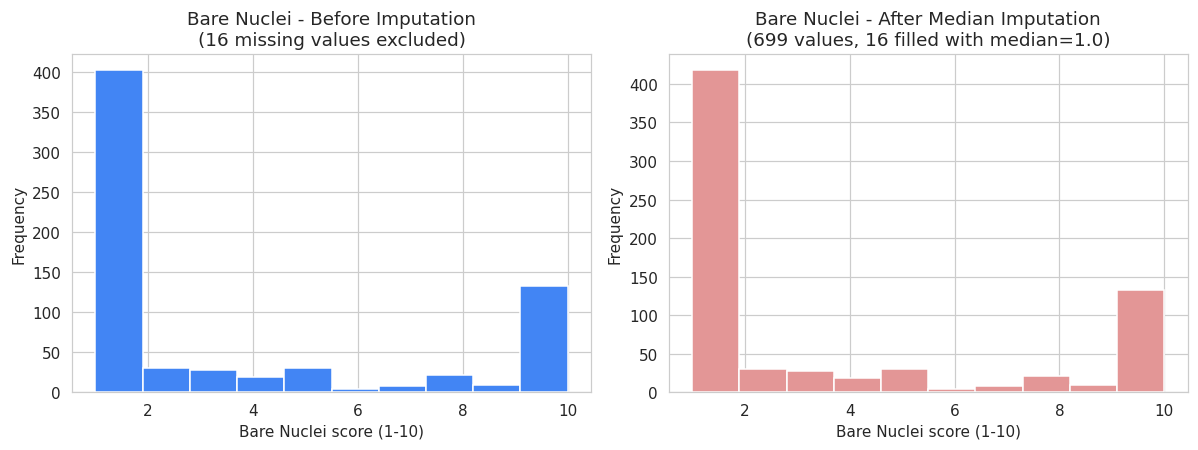

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].hist(df_clean['Bare_Nuclei'].dropna(), bins=10, color='#4285F4', edgecolor='white')
axes[0].set_title('Bare Nuclei - Before Imputation\n(16 missing values excluded)')
axes[0].set_xlabel('Bare Nuclei score (1-10)')
axes[0].set_ylabel('Frequency')

axes[1].hist(df_imputed['Bare_Nuclei'], bins=10, color='#E39696', edgecolor='white')
axes[1].set_title('Bare Nuclei - After Median Imputation\n(699 values, 16 filled with median=1.0)')
axes[1].set_xlabel('Bare Nuclei score (1-10)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.savefig(f'{VIZ_DIR}/01_missing_data_bare_nuclei_imputation.png', bbox_inches='tight')
plt.show()

**Interpretation:** The distribution is strongly bimodal/right-skewed - most tumours score a **Bare_Nuclei** value of 1 (benign-leaning), with a smaller cluster of high scores (8-10, malignant-leaning). After median imputation, the overall **shape of the distribution is preserved** - the 16 newly filled values all land in the already-dominant lowest bin, so imputation did not distort the feature's relationship with the target class. This confirms median imputation was a safe, low-risk choice for this feature.

## 5. Summary
| Item | Result |
|---|---|
| Technique | Missing data handling - median imputation |
| Affected column | **Bare_Nuclei** |
| Missing values | 16 / 699 (2.29%) |
| Method chosen | Median imputation (median = mode = 1.0) |
| Why not mean? | Distribution is right-skewed; mean (3.54) would distort the majority-low pattern |
| Why not deletion? | Only 2.3% of data - deleting would discard potentially informative malignant cases for little benefit |
| Rows after processing | 699 (unchanged) |